In [1]:
import pandas as pd  # Importar pandas para manejo de datos
from sklearn.model_selection import train_test_split  # Importar función para dividir datos
from sklearn.linear_model import LogisticRegression  # Importar modelo de Regresión Logística
from sklearn.metrics import classification_report  # Importar reporte de métricas
from sklearn import metrics  # Importar módulo de métricas generales
import matplotlib.pyplot as plt  # Importar módulo para graficar
import warnings  # Importar módulo de advertencias del sistema
warnings.filterwarnings("ignore")  # Ocultar advertencias en la salida

from sklearn import preprocessing

In [17]:
drugs = pd.read_csv("drugs.csv")

drugs

,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,F,HIGH,HIGH,25.355,drugY
1,47,M,LOW,HIGH,13.093,drugC
2,47,M,LOW,HIGH,10.114,drugC
3,28,F,NORMAL,HIGH,7.798,drugX
4,61,F,LOW,HIGH,18.043,drugY
...,...,...,...,...,...,...
195,56,F,LOW,HIGH,11.567,drugC
196,16,M,LOW,HIGH,12.006,drugC
197,52,M,NORMAL,HIGH,9.894,drugX
198,23,M,NORMAL,NORMAL,14.020,drugX


In [19]:
le = preprocessing.LabelEncoder()

drugs["Sex"] = le.fit_transform(drugs["Sex"])
drugs["BP"] = le.fit_transform(drugs["BP"])
drugs["Cholesterol"] = le.fit_transform(drugs["Cholesterol"])

drugs

,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,0,0,0,25.355,drugY
1,47,1,1,0,13.093,drugC
2,47,1,1,0,10.114,drugC
3,28,0,2,0,7.798,drugX
4,61,0,1,0,18.043,drugY
...,...,...,...,...,...,...
195,56,0,1,0,11.567,drugC
196,16,1,1,0,12.006,drugC
197,52,1,2,0,9.894,drugX
198,23,1,2,1,14.020,drugX


In [21]:
feature_cols = ["Age", "Sex", "BP", "Cholesterol", "Na_to_K"]

X = drugs[feature_cols]
y = drugs.Drug

In [23]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [25]:
# sag: Stochastic Average Gradient
# newton-cg: Newton
# liblinear: Library for large linear classification (Algoritmo Coordiante Descent)
# saga: Variante del método sag
# lbfgs: Limited-memory Broyden-Fletcher-Goldfarb-Shanno Algorithm

# Regresión logistica con solucionador (solver): sag

In [28]:
model = LogisticRegression(solver="sag", max_iter=5000)  # Crear modelo
clf = model.fit(X_train, y_train)  # Entrenar modelo

y_pred = model.predict(X_test) # Generar predicciones

print("Intercepto (Beta 0)", clf.intercept_)  # Imprimir intercepto
print("Pesos de cada variable", clf.coef_)  # Imprimir coeficientes
print("----------------------------------------------------------------------------------------------------")  # Separador
score = model.score(X_test, y_test)  # Calcular exactitud del modelo
print("Score de precisión: ", score)  # Imprimir precisión global
print("----------------------------------------------------------------------------------------------------")  # Separador
print(classification_report(y_test, y_pred))  # Generar e imprimir reporte de clasificación

Intercepto (Beta 0) [ 1.93006134 -0.44095773  1.05175167  1.17734224 -3.71819752]
Pesos de cada variable [[-0.03896883  0.54468834 -1.85255589  0.1716916   0.06754194]
 [ 0.08773663 -0.45373281 -1.86809676 -0.32797611 -0.23642377]
 [ 0.00481028  0.34113452  0.64822367 -1.31051356 -0.09934298]
 [-0.0074779  -0.21544033  2.7363331   1.61368079 -0.26110445]
 [-0.04610017 -0.21664972  0.33609587 -0.14688272  0.52932926]]
Score de precisión:  0.825
              precision    recall  f1-score   support

       drugA       0.60      0.60      0.60         5
       drugB       0.67      0.67      0.67         3
       drugC       0.00      0.00      0.00         3
       drugX       0.85      1.00      0.92        11
       drugY       0.89      0.94      0.92        18

    accuracy                           0.82        40
   macro avg       0.60      0.64      0.62        40
weighted avg       0.76      0.82      0.79        40



# Regresión logistica con solucionador (solver): newton-cg

In [31]:
model = LogisticRegression(solver="newton-cg", max_iter=5000)  # Crear modelo
clf = model.fit(X_train, y_train)  # Entrenar modelo

y_pred = model.predict(X_test) # Generar predicciones

print("Intercepto (Beta 0)", clf.intercept_)  # Imprimir intercepto
print("Pesos de cada variable", clf.coef_)  # Imprimir coeficientes
print("----------------------------------------------------------------------------------------------------")  # Separador
score = model.score(X_test, y_test)  # Calcular exactitud del modelo
print("Score de precisión: ", score)  # Imprimir precisión global
print("----------------------------------------------------------------------------------------------------")  # Separador
print(classification_report(y_test, y_pred))  # Generar e imprimir reporte de clasificación

Intercepto (Beta 0) [ 13.28282314   0.51183596  10.04298807   5.94978223 -29.78742939]
Pesos de cada variable [[-0.08445161  0.21677249 -2.24855546 -0.11078545 -0.59126404]
 [ 0.1252697  -0.35650503 -1.88530262 -0.1658804  -0.40703985]
 [-0.01442366  0.12145191  0.6077703  -1.55563146 -0.65299598]
 [-0.00942139 -0.26535703  3.00921211  1.77325946 -0.55324604]
 [-0.01697304  0.28363765  0.51687567  0.05903785  2.20454591]]
Score de precisión:  0.95
              precision    recall  f1-score   support

       drugA       0.83      1.00      0.91         5
       drugB       1.00      0.67      0.80         3
       drugC       1.00      0.67      0.80         3
       drugX       1.00      1.00      1.00        11
       drugY       0.95      1.00      0.97        18

    accuracy                           0.95        40
   macro avg       0.96      0.87      0.90        40
weighted avg       0.96      0.95      0.95        40



# Regresión logistica con solucionador (solver): liblinear

In [42]:
model = LogisticRegression(solver="liblinear", max_iter=5000)  # Crear modelo
clf = model.fit(X_train, y_train)  # Entrenar modelo

y_pred = model.predict(X_test) # Generar predicciones

print("Intercepto (Beta 0)", clf.intercept_)  # Imprimir intercepto
print("Pesos de cada variable", clf.coef_)  # Imprimir coeficientes
print("----------------------------------------------------------------------------------------------------")  # Separador
score = model.score(X_test, y_test)  # Calcular exactitud del modelo
print("Score de precisión: ", score)  # Imprimir precisión global
print("----------------------------------------------------------------------------------------------------")  # Separador
print(classification_report(y_test, y_pred))  # Generar e imprimir reporte de clasificación

Intercepto (Beta 0) [ 2.13294903 -0.654539    0.65134439  0.74985306 -4.50607304]
Pesos de cada variable [[-3.03921461e-02  6.36404742e-01 -2.31803040e+00 -2.05005963e-03
  -1.61430512e-01]
 [ 9.57026829e-02 -6.57835175e-01 -2.56532889e+00 -4.75734628e-01
  -3.85623106e-01]
 [ 4.77133694e-03  2.28355438e-01 -2.18157674e-02 -1.95363101e+00
  -2.18662663e-01]
 [ 3.42207734e-03 -3.72857941e-01  2.89151311e+00  1.98560334e+00
  -4.74792680e-01]
 [-4.08124712e-02 -3.59231054e-01 -2.32425914e-01 -5.63935718e-01
   4.68941024e-01]]
Score de precisión:  0.85
              precision    recall  f1-score   support

       drugA       0.75      0.60      0.67         5
       drugB       0.67      0.67      0.67         3
       drugC       0.00      0.00      0.00         3
       drugX       0.85      1.00      0.92        11
       drugY       0.90      1.00      0.95        18

    accuracy                           0.85        40
   macro avg       0.63      0.65      0.64        40
weighted 

# Regresión logistica con solucionador (solver): saga

In [37]:
model = LogisticRegression(solver="saga", max_iter=5000)  # Crear modelo
clf = model.fit(X_train, y_train)  # Entrenar modelo

y_pred = model.predict(X_test) # Generar predicciones

print("Intercepto (Beta 0)", clf.intercept_)  # Imprimir intercepto
print("Pesos de cada variable", clf.coef_)  # Imprimir coeficientes
print("----------------------------------------------------------------------------------------------------")  # Separador
score = model.score(X_test, y_test)  # Calcular exactitud del modelo
print("Score de precisión: ", score)  # Imprimir precisión global
print("----------------------------------------------------------------------------------------------------")  # Separador
print(classification_report(y_test, y_pred))  # Generar e imprimir reporte de clasificación

Intercepto (Beta 0) [ 1.50988294 -0.34845262  0.77959451  1.00300138 -2.94402621]
Pesos de cada variable [[-0.03625062  0.52934929 -1.75501546  0.2103289   0.08379143]
 [ 0.08378626 -0.41192033 -1.73016217 -0.29070745 -0.235873  ]
 [ 0.00641971  0.32433228  0.61077846 -1.19956144 -0.08824642]
 [-0.00613864 -0.16953578  2.61705636  1.50960701 -0.24520913]
 [-0.0478167  -0.27222546  0.25734281 -0.22966702  0.48553712]]
Score de precisión:  0.825
              precision    recall  f1-score   support

       drugA       0.60      0.60      0.60         5
       drugB       0.67      0.67      0.67         3
       drugC       0.00      0.00      0.00         3
       drugX       0.85      1.00      0.92        11
       drugY       0.89      0.94      0.92        18

    accuracy                           0.82        40
   macro avg       0.60      0.64      0.62        40
weighted avg       0.76      0.82      0.79        40



# Regresión logistica con solucionador (solver): lbfgs

In [40]:
model = LogisticRegression(solver="lbfgs", max_iter=5000)  # Crear modelo
clf = model.fit(X_train, y_train)  # Entrenar modelo

y_pred = model.predict(X_test) # Generar predicciones

print("Intercepto (Beta 0)", clf.intercept_)  # Imprimir intercepto
print("Pesos de cada variable", clf.coef_)  # Imprimir coeficientes
print("----------------------------------------------------------------------------------------------------")  # Separador
score = model.score(X_test, y_test)  # Calcular exactitud del modelo
print("Score de precisión: ", score)  # Imprimir precisión global
print("----------------------------------------------------------------------------------------------------")  # Separador
print(classification_report(y_test, y_pred))  # Generar e imprimir reporte de clasificación

Intercepto (Beta 0) [ 13.30471623   0.47623707  10.02990899   5.96823682 -29.77909911]
Pesos de cada variable [[-0.08461645  0.21534552 -2.24809028 -0.11222395 -0.59245015]
 [ 0.1255663  -0.35562084 -1.88584315 -0.16547416 -0.40564732]
 [-0.01444396  0.12335748  0.6093126  -1.55398479 -0.65186305]
 [-0.00955572 -0.26658935  3.00854997  1.77286219 -0.55404783]
 [-0.01695017  0.28350719  0.51607086  0.05882071  2.20400834]]
Score de precisión:  0.95
              precision    recall  f1-score   support

       drugA       0.83      1.00      0.91         5
       drugB       1.00      0.67      0.80         3
       drugC       1.00      0.67      0.80         3
       drugX       1.00      1.00      1.00        11
       drugY       0.95      1.00      0.97        18

    accuracy                           0.95        40
   macro avg       0.96      0.87      0.90        40
weighted avg       0.96      0.95      0.95        40



In [60]:
# Predicción de probabilidades para casos particulares
y_pred_probs = clf.predict_proba(X_test)

y_pred_probs[0:5]

array([[5.29730777e-02, 9.66987543e-02, 2.89560646e-01, 3.83752346e-01,
        1.77015176e-01],
       [7.65121897e-02, 2.66376083e-02, 4.96902065e-02, 7.43854627e-01,
        1.03305369e-01],
       [3.17900198e-01, 4.00112927e-01, 2.32410465e-01, 2.93259298e-02,
        2.02504811e-02],
       [6.93257378e-03, 2.76885902e-03, 2.22515250e-01, 7.23228129e-01,
        4.45551885e-02],
       [4.76372201e-02, 2.56308655e-04, 6.25222001e-03, 2.89667193e-06,
        9.45851355e-01]])

In [62]:
y_test[0:5]

array(['drugC', 'drugX', 'drugA', 'drugX', 'drugY'], dtype=object)

In [66]:
from sklearn.preprocessing import label_binarize

classes = clf.classes_

y_test_bin = label_binarize(y_test, classes=classes)

y_test_bin[0:5]

array([[0, 0, 1, 0, 0],
       [0, 0, 0, 1, 0],
       [1, 0, 0, 0, 0],
       [0, 0, 0, 1, 0],
       [0, 0, 0, 0, 1]])

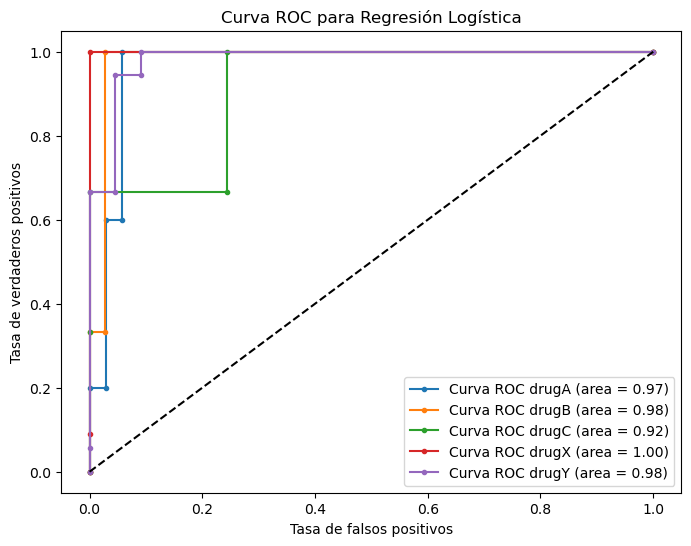

In [68]:
# Graficación de la curva ROC y cálculo del área bajo ella

from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score

plt.figure(figsize=(8,6))

for i in range(len(classes)):

    # fpr = false positive rate
    # tpr = true positive rate
    # thresholds = límites para valores de p

    fpr, tpr, thresholds = roc_curve(y_test_bin[:,i],y_pred_probs[:,i])
    auc = roc_auc_score(y_test_bin[:,i],y_pred_probs[:,i])
    plt.plot(fpr,tpr,marker=".",label="Curva ROC {} (area = {:.2f})".format(classes[i], auc))

plt.plot([0,1], [0,1], 'k--')
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.legend(loc="lower right")
plt.title("Curva ROC para Regresión Logística")
plt.show()

# ¿Qué tan eficaz es el algoritmo predictivo escogido?

El modelo obtenido mediante Newton-CG presentó una precisión global del 95%, lo que indica que clasificó correctamente 38 de las 40 observaciones del conjunto de prueba. El F1 macro fue de aproximadamente 0.896, mostrando un buen equilibrio entre precisión y sensibilidad entre las diferentes clases. Sin embargo, las clases drugB y drugC presentaron un recall de aproximadamente 0.667, por lo que el modelo tuvo algunas dificultades para identificar todos los casos pertenecientes a estas categorías. En contraste, drugX y drugY presentaron un desempeño muy alto.
La curva ROC también mostró un desempeño excelente, con un AUC macro aproximado de 0.997. Esto indica que el modelo tiene una capacidad muy alta para distinguir entre las diferentes categorías de medicamentos. Por lo tanto, considerando conjuntamente la precisión, el reporte de clasificación y el AUC, el algoritmo seleccionado presenta un desempeño predictivo muy bueno para esta base de datos.